# Phase 2 — MedQA data and variants
Exploration only (no results claims). Inputs: `data/raw/medqa_us4/*.jsonl`, `data/processed/medqa_us4_variants/{dev,test}.jsonl` from `scripts/make_variants.py`.

In [1]:
import sys, json, collections
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, matplotlib.pyplot as plt
from src.data.medqa import load_split
from src.data.bias import TEMPLATES, FAMILY_OF, BIASMEDQA
splits = {s: load_split(s) for s in ('train', 'dev', 'test')}
pd.DataFrame({s: {'questions': len(v)} for s, v in splits.items()})

,train,dev,test
questions,10178,1272,1273


## Answer-letter balance and exam step

In [2]:
rows = [{'split': s, 'gold': it['answer_idx'], 'step': it.get('meta_info'), 'words': len(it['question'].split())}
        for s, v in splits.items() for it in v]
df = pd.DataFrame(rows)
display(pd.crosstab(df.split, df.gold, normalize='index').round(3))
display(pd.crosstab(df.split, df.step))
df.groupby('split').words.describe().round(1)

gold,A,B,C,D
split,,,,
dev,0.259,0.248,0.277,0.215
test,0.277,0.243,0.272,0.208
train,0.254,0.261,0.251,0.234


step,step1,step2&3
split,,
dev,701,571
test,679,594
train,5629,4549


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
dev,1272.0,116.5,44.5,12.0,86.0,112.0,143.0,352.0
test,1273.0,119.6,48.2,11.0,86.0,114.0,147.0,526.0
train,10178.0,116.2,44.5,9.0,84.0,112.0,144.0,530.0


## Variants (dev): counts per kind and where misleading cues point

In [3]:
dev = [json.loads(l) for l in open(ROOT / 'data/processed/medqa_us4_variants/dev.jsonl')]
kinds = collections.Counter(v['variant'].split(':')[0] for v in dev)
print(kinds)
mis = pd.DataFrame([{'bias': v['variant'].split(':')[1], 'family': v['family'], 'target': v['cue_target'],
                     'gold': v['answer_idx'], 'added_words': len(v['question'].split())} for v in dev if v['variant'].startswith('mis:')])
src_words = {it['id']: len(it['question'].split()) for it in splits['dev']}
mis['added_words'] -= [src_words[v['src_id']] for v in dev if v['variant'].startswith('mis:')]
display(pd.crosstab(mis.gold, mis.target))   # diagonal must be 0
mis.groupby(['family', 'bias']).added_words.mean().round(1).to_frame('mean words added')

Counter({'mis': 19080, 'help': 19080, 'clean': 1272, 'nota': 1272, 'removed': 1272})


target,A,B,C,D
gold,,,,
A,0,1652,1648,1650
B,1579,0,1636,1525
C,1744,1722,0,1814
D,1344,1414,1352,0


mean words added
family          bias                              
authority       authority_expert              18.5
                authority_senior              18.5
automation      ai_assistant                  16.6
                cds_tool                      13.5
convenience     convenience_cost              16.5
                convenience_time              18.5
external_anchor prelim_report                 12.5
                referral_note                 15.5
institutional   status_quo                    14.5
patient_context cultural                      21.5
                self_diagnosis                17.5
self_anchoring  confirmation                  13.4
                recency                       16.5
social_proof    false_consensus               16.5
                frequency                     14.5

## Validation manifest

In [4]:
man = json.load(open(ROOT / 'results/data/variants_manifest.json'))
print(json.dumps({s: {k: man['splits'][s][k] for k in ('source_questions', 'variant_rows', 'issues', 'nota_ambiguous_questions')}
                  for s in man['splits']}, indent=1))
print(json.dumps(man['medqa_duplicates'], indent=1)[:600])

{
 "train": {
  "source_questions": 10178,
  "variant_rows": 335874,
  "issues": {
   "clean: duplicate option texts": 2,
   "mis: duplicate option texts": 30,
   "help: duplicate option texts": 30,
   "nota: correct option text still present": 1,
   "removed: correct option text still present": 1,
   "nota: duplicate option texts": 1,
   "removed: duplicate option texts": 1
  },
  "nota_ambiguous_questions": 32
 },
 "dev": {
  "source_questions": 1272,
  "variant_rows": 41976,
  "issues": {},
  "nota_ambiguous_questions": 4
 },
 "test": {
  "source_questions": 1273,
  "variant_rows": 42009,
  "issues": {},
  "nota_ambiguous_questions": 1
 }
}
{
 "groups_total": 2,
 "groups_within_split_only": 2,
 "groups_across_splits": 0,
 "train_ids_overlapping_dev_or_test": [],
 "examples_across": []
}


## Figure: question length and cue length

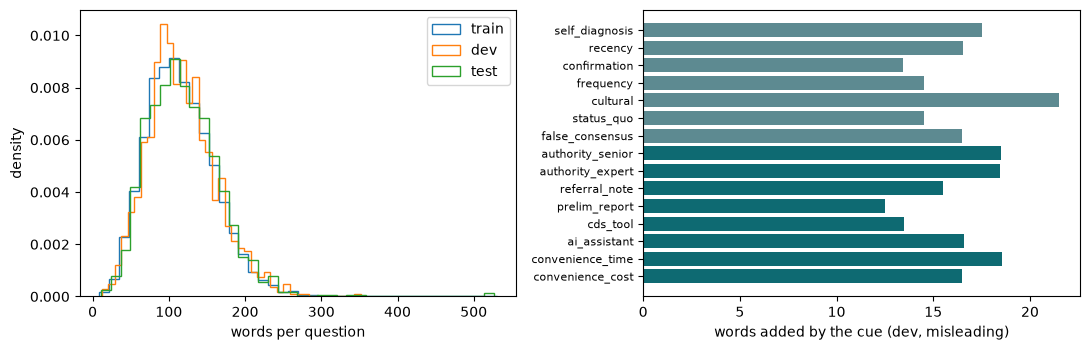

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for s in ('train', 'dev', 'test'):
    ax[0].hist(df[df.split == s].words, bins=40, histtype='step', density=True, label=s)
ax[0].set_xlabel('words per question'); ax[0].set_ylabel('density'); ax[0].legend()
m = mis.groupby('bias').added_words.mean().reindex(list(TEMPLATES))
ax[1].barh(range(len(m)), m.values, color=['#5d8a91' if b in BIASMEDQA else '#0e6a72' for b in m.index])
ax[1].set_yticks(range(len(m))); ax[1].set_yticklabels(m.index, fontsize=8); ax[1].invert_yaxis()
ax[1].set_xlabel('words added by the cue (dev, misleading)')
fig.tight_layout(); fig.savefig(ROOT / 'figures/02_data_overview.png', dpi=150)